In [1]:
# ==========================================
# TerraSpectra - MobileNetV2 Transfer Learning
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 4

CLASS_NAMES = [
    "Black rot",
    "Esca",
    "Healthy",
    "Leaf blight"
]

print("\nClasses:", CLASS_NAMES)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.21.0
GPU available: []

Classes: ['Black rot', 'Esca', 'Healthy', 'Leaf blight']
Image size: (224, 224)
Batch size: 32


In [2]:
# Load the existing vineyard-aware splits

DATA_DIR = "../data/processed"

train_df = pd.read_csv(f"{DATA_DIR}/splits/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/splits/validation.csv")
test_df = pd.read_csv(f"{DATA_DIR}/splits/test.csv")

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nTrain sample:")
display(train_df.head())

print("\nValidation sample:")
display(val_df.head())

print("\nTest sample:")
display(test_df.head())

Train shape: (2525, 9)
Validation shape: (490, 9)
Test shape: (462, 9)

Train columns:
['image_path', 'filename', 'label', 'vineyard_id', 'latitude', 'longitude', 'timestamp', 'lighting', 'weather']

Train sample:


,image_path,filename,label,vineyard_id,latitude,longitude,timestamp,lighting,weather
0,../data/processed/GVLiD_224\Black rot\black ro...,black rot001.jpg,Black rot,Vineyard_22,18.785238,73.994949,2023-06-15 15:13:00+05:30,Overcast,Humid
1,../data/processed/GVLiD_224\Black rot\black ro...,black rot002.jpg,Black rot,Vineyard_28,18.731029,73.977206,2023-06-15 12:58:00+05:30,Natural sunlight,Humid
2,../data/processed/GVLiD_224\Black rot\black ro...,black rot003.jpg,Black rot,Vineyard_14,18.802297,74.027516,2023-06-15 12:36:00+05:30,Partly cloudy,Humid
3,../data/processed/GVLiD_224\Black rot\black ro...,black rot005.jpg,Black rot,Vineyard_8,18.790580,74.002429,2023-06-15 18:02:00+05:30,Partly cloudy,Clear
4,../data/processed/GVLiD_224\Black rot\black ro...,black rot006.jpg,Black rot,Vineyard_22,18.785238,73.994949,2023-06-15 13:27:00+05:30,Partly cloudy,Humid



Validation sample:


,image_path,filename,label,vineyard_id,latitude,longitude,timestamp,lighting,weather
0,../data/processed/GVLiD_224\Black rot\black ro...,black rot004.jpg,Black rot,Vineyard_20,18.775820,74.000550,2023-06-15 08:40:00+05:30,Overcast,Humid
1,../data/processed/GVLiD_224\Black rot\black ro...,black rot008.jpg,Black rot,Vineyard_4,18.770889,74.024265,2023-06-15 07:56:00+05:30,Overcast,Windy
2,../data/processed/GVLiD_224\Black rot\black ro...,black rot011.jpg,Black rot,Vineyard_4,18.770889,74.024265,2023-06-15 07:52:00+05:30,Overcast,Clear
3,../data/processed/GVLiD_224\Black rot\black ro...,black rot025.jpg,Black rot,Vineyard_25,18.753966,74.028567,2023-06-15 10:16:00+05:30,Partly cloudy,Humid
4,../data/processed/GVLiD_224\Black rot\black ro...,black rot053.jpg,Black rot,Vineyard_4,18.770889,74.024265,2023-06-15 17:31:00+05:30,Overcast,Humid



Test sample:


,image_path,filename,label,vineyard_id,latitude,longitude,timestamp,lighting,weather
0,../data/processed/GVLiD_224\Black rot\black ro...,black rot015.jpg,Black rot,Vineyard_7,18.821137,74.049740,2023-06-15 07:37:00+05:30,Partly cloudy,Humid
1,../data/processed/GVLiD_224\Black rot\black ro...,black rot026.jpg,Black rot,Vineyard_7,18.821137,74.049740,2023-06-15 10:29:00+05:30,Natural sunlight,Windy
2,../data/processed/GVLiD_224\Black rot\black ro...,black rot038.jpg,Black rot,Vineyard_17,18.750256,73.990160,2023-06-15 13:41:00+05:30,Partly cloudy,Humid
3,../data/processed/GVLiD_224\Black rot\black ro...,black rot046.jpg,Black rot,Vineyard_17,18.750256,73.990160,2023-06-15 09:01:00+05:30,Partly cloudy,Windy
4,../data/processed/GVLiD_224\Black rot\black ro...,black rot051.jpg,Black rot,Vineyard_3,18.816013,73.979374,2023-06-15 18:57:00+05:30,Partly cloudy,Humid


In [5]:
# ==========================================
# Correct image paths
# ==========================================

from pathlib import Path

CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "data").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError("Could not locate project data directory")

IMAGE_ROOT = PROJECT_ROOT / "data" / "processed" / "GVLiD_224"

# Normalize labels to match folder names
folder_mapping = {
    "black rot": "Black rot",
    "esca": "esca",
    "healthy": "healthy",
    "leaf blight": "leaf blight"
}

def build_image_path(row):
    normalized_label = row["label"].strip().lower()
    folder = folder_mapping[normalized_label]

    return IMAGE_ROOT / folder / row["filename"]

# Create image paths
train_df["image_path"] = train_df.apply(build_image_path, axis=1)
val_df["image_path"] = val_df.apply(build_image_path, axis=1)
test_df["image_path"] = test_df.apply(build_image_path, axis=1)

# Verify paths
print("Project root:", PROJECT_ROOT)
print("Image root:", IMAGE_ROOT)

print("\nSample image:")
print(train_df["image_path"].iloc[0])

print("\nTrain image exists:", train_df["image_path"].iloc[0].exists())
print("Validation image exists:", val_df["image_path"].iloc[0].exists())
print("Test image exists:", test_df["image_path"].iloc[0].exists())

# Check missing files
missing_train = (~train_df["image_path"].apply(lambda x: x.exists())).sum()
missing_val = (~val_df["image_path"].apply(lambda x: x.exists())).sum()
missing_test = (~test_df["image_path"].apply(lambda x: x.exists())).sum()

print("\nMissing train images:", missing_train)
print("Missing validation images:", missing_val)
print("Missing test images:", missing_test)

Project root: c:\intern project 2\TerraSpectra-
Image root: c:\intern project 2\TerraSpectra-\data\processed\GVLiD_224

Sample image:
c:\intern project 2\TerraSpectra-\data\processed\GVLiD_224\Black rot\black rot001.jpg

Train image exists: True
Validation image exists: True
Test image exists: True

Missing train images: 0
Missing validation images: 0
Missing test images: 0


In [6]:
# ==========================================
# TensorFlow Dataset Pipeline
# ==========================================

AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 16  # Smaller batch for CPU training

# Convert image paths and labels into arrays
X_train_paths = train_df["image_path"].astype(str).values
y_train = train_df["label"].str.strip().str.lower().map({
    "black rot": 0,
    "esca": 1,
    "healthy": 2,
    "leaf blight": 3
}).values.astype(np.int32)

X_val_paths = val_df["image_path"].astype(str).values
y_val = val_df["label"].str.strip().str.lower().map({
    "black rot": 0,
    "esca": 1,
    "healthy": 2,
    "leaf blight": 3
}).values.astype(np.int32)

X_test_paths = test_df["image_path"].astype(str).values
y_test = test_df["label"].str.strip().str.lower().map({
    "black rot": 0,
    "esca": 1,
    "healthy": 2,
    "leaf blight": 3
}).values.astype(np.int32)

print("Training samples:", len(X_train_paths))
print("Validation samples:", len(X_val_paths))
print("Test samples:", len(X_test_paths))

print("\nLabel encoding:")
print(label_to_index)

Training samples: 2525
Validation samples: 490
Test samples: 462

Label encoding:
{'Black rot': 0, 'Esca': 1, 'Healthy': 2, 'Leaf blight': 3}


In [7]:
# ==========================================
# Image preprocessing function
# ==========================================

def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    # MobileNetV2 preprocessing
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label

In [8]:
# ==========================================
# Create datasets
# ==========================================

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_paths, y_train)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_paths, y_val)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_paths, y_test)
)

# Training dataset
train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(X_train_paths), seed=SEED)
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Validation dataset
val_dataset = (
    val_dataset
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Test dataset
test_dataset = (
    test_dataset
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [9]:
# ==========================================
# Verify dataset batches
# ==========================================

for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>
Minimum pixel value: -1.0
Maximum pixel value: 1.0


In [10]:
# ==========================================
# MobileNetV2 Transfer Learning Model
# ==========================================

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

print("Base model loaded successfully!")
print("Total base model layers:", len(base_model.layers))
print("Trainable base model:", base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step
Base model loaded successfully!
Total base model layers: 154
Trainable base model: False


In [11]:
# ==========================================
# Custom Classification Head
# ==========================================

inputs = keras.Input(shape=(224, 224, 3))

# Pretrained feature extractor
x = base_model(inputs, training=False)

# Global average pooling
x = layers.GlobalAveragePooling2D()(x)

# Regularization
x = layers.Dropout(0.3)(x)

# Dense classification layer
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="disease_predictions"
)(x)

mobilenet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="TerraSpectra_MobileNetV2"
)

mobilenet_model.summary()

Model: "TerraSpectra_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_predictions (Dense)     │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
# ==========================================
# Compile Model
# ==========================================

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [13]:
# ==========================================
# Training Callbacks
# ==========================================

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

checkpoint_path = MODEL_DIR / "mobilenetv2_best.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configured!")
print("Checkpoint:", checkpoint_path)    

Callbacks configured!
Checkpoint: c:\intern project 2\TerraSpectra-\models\mobilenetv2_best.keras


In [14]:
# ==========================================
# Phase 1: Train Classification Head
# ==========================================

EPOCHS_HEAD = 10

history_mobilenet = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks
)

Epoch 1/10


c:\Users\shewa\anaconda3\envs\terraspectra\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.6808 - loss: 0.8118
Epoch 1: val_accuracy improved from None to 0.81837, saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_best.keras

Epoch 1: finished saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_best.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 42s 240ms/step - accuracy: 0.6808 - loss: 0.8118 - val_accuracy: 0.8184 - val_loss: 0.4897 - learning_rate: 0.0010
Epoch 2/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.8178 - loss: 0.4638
Epoch 2: val_accuracy improved from 0.81837 to 0.82245, saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_best.keras

Epoch 2: finished saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_best.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 36s 229ms/step - accuracy: 0.8178 - loss: 0.4638 - val_accuracy: 0.8224 - val_loss: 0.4495 - learning_rate: 0.0010
Epoch 3/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.8420 - loss:

In [15]:
# ==========================================
# Phase 2: Fine-Tuning MobileNetV2
# ==========================================

# Unfreeze the base model
base_model.trainable = True

# Freeze most layers and train only the top layers
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Total layers:", len(base_model.layers))
print("Fine-tuning from layer:", fine_tune_at)

print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model.layers)
)

print(
    "Trainable parameters:",
    sum(
        tf.keras.backend.count_params(weight)
        for weight in mobilenet_model.trainable_weights
    )
)

Total layers: 154
Fine-tuning from layer: 124
Trainable layers: 19
Trainable parameters: 1515844


In [16]:
# ==========================================
# Recompile for Fine-Tuning
# ==========================================

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [17]:
# ==========================================
# Fine-Tuning Training
# ==========================================

EPOCHS_FINE_TUNE = 5

history_fine = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=callbacks
)

Epoch 1/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.8982 - loss: 0.2359
Epoch 1: val_accuracy improved from 0.86327 to 0.86735, saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_best.keras

Epoch 1: finished saving model to c:\intern project 2\TerraSpectra-\models\mobilenetv2_best.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 45s 263ms/step - accuracy: 0.8982 - loss: 0.2359 - val_accuracy: 0.8673 - val_loss: 0.2635 - learning_rate: 1.0000e-05
Epoch 2/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9069 - loss: 0.2040
Epoch 2: val_accuracy did not improve from 0.86735
158/158 ━━━━━━━━━━━━━━━━━━━━ 37s 233ms/step - accuracy: 0.9069 - loss: 0.2040 - val_accuracy: 0.8592 - val_loss: 0.2787 - learning_rate: 1.0000e-05
Epoch 3/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.9184 - loss: 0.1774
Epoch 3: val_accuracy did not improve from 0.86735
158/158 ━━━━━━━━━━━━━━━━━━━━ 39s 246ms/step - accuracy: 0.9184 - loss: 0.1774 - val_accuracy: 0.8673 - val

In [18]:
# Evaluate MobileNetV2 on the untouched test dataset

test_loss, test_accuracy = mobilenet_model.evaluate(test_dataset)

print("\nMobileNetV2 Test Results")
print("-" * 40)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 206ms/step - accuracy: 0.8550 - loss: 0.3019

MobileNetV2 Test Results
----------------------------------------
Test Loss: 0.3019
Test Accuracy: 85.4978%


In [20]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Generate predictions
y_prob = mobilenet_model.predict(test_dataset)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print("MobileNetV2 Classification Report")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 193ms/step
MobileNetV2 Classification Report
              precision    recall  f1-score   support

   Black rot     0.9717    1.0000    0.9856       103
        Esca     0.7444    0.7674    0.7557       129
     Healthy     0.9932    0.9864    0.9898       147
 Leaf blight     0.6234    0.5783    0.6000        83

    accuracy                         0.8550       462
   macro avg     0.8331    0.8330    0.8328       462
weighted avg     0.8525    0.8550    0.8535       462



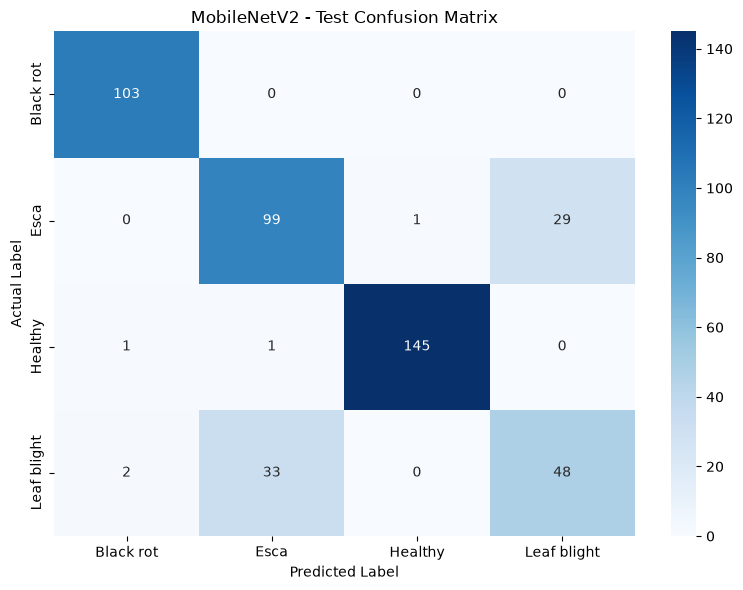

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("MobileNetV2 - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

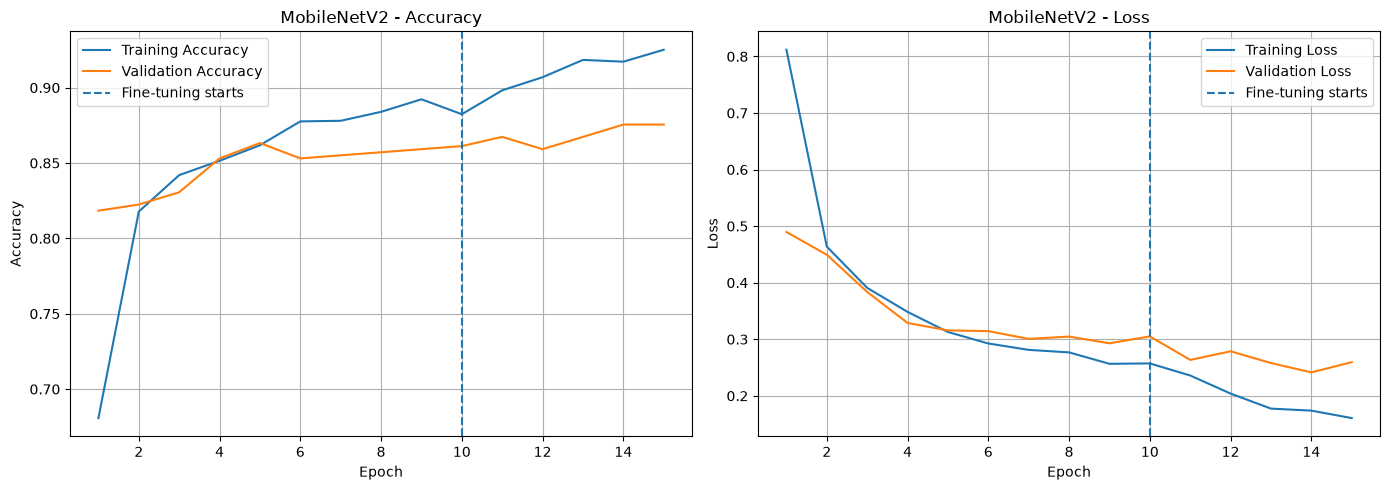

In [22]:
# Combine Phase 1 and Phase 2 histories

train_acc = (
    history_mobilenet.history["accuracy"]
    + history_fine.history["accuracy"]
)

val_acc = (
    history_mobilenet.history["val_accuracy"]
    + history_fine.history["val_accuracy"]
)

train_loss = (
    history_mobilenet.history["loss"]
    + history_fine.history["loss"]
)

val_loss = (
    history_mobilenet.history["val_loss"]
    + history_fine.history["val_loss"]
)

epochs = range(1, len(train_acc) + 1)

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.axvline(
    x=len(history_mobilenet.history["accuracy"]),
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("MobileNetV2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.axvline(
    x=len(history_mobilenet.history["loss"]),
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("MobileNetV2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()